# AulaSense: Comparación de propuestas arquitectónicas

## Objetivo

Comparar las cuatro propuestas de mejora del diseño de AulaSense,
considerando la distribución de responsabilidades, la cohesión,
el acoplamiento, la facilidad de mantenimiento, las pruebas
y la posibilidad de ampliar el sistema.

## Propuestas desarrolladas

- **Versión A — David:** Arquitectura por capas.
- **Versión B — Ricardo:** Arquitectura orientada a eventos.
- **Versión C — Javier:** Adaptadores y estrategias para sensores.
- **Versión D — Daniela:** Separación del registro y las consultas.

## Propósito de la comparación

Identificar las ventajas y limitaciones de cada propuesta para
determinar qué organización de clases resulta más conveniente
para el proyecto AulaSense.

## Comparación de las cuatro propuestas

| Criterio | David: Por capas | Ricardo: Por eventos | Javier: Adaptadores y estrategias | Daniela: Registro y consultas |
|---|---|---|---|---|
| Organización | Divide el sistema en capas con funciones específicas. | Separa los componentes mediante eventos. | Organiza el manejo de sensores mediante adaptadores y estrategias. | Separa el registro, las consultas, los reportes y la visualización. |
| Cohesión | Alta, porque cada capa tiene una función definida. | Alta, porque cada manejador atiende un tipo de evento. | Alta, porque cada componente se especializa en sensores o estrategias. | Alta, porque cada clase tiene una responsabilidad concreta. |
| Acoplamiento | Moderado, debido a las dependencias entre capas. | Potencialmente bajo, gracias a la comunicación mediante eventos. | Bajo entre el monitoreo y los sensores concretos, si se utilizan interfaces. | Moderado, porque los servicios comparten el almacenamiento. |
| Mantenimiento | Facilita localizar cambios en cada capa. | Permite modificar manejadores sin alterar todos los componentes. | Facilita actualizar sensores o estrategias individuales. | Permite modificar consultas o reportes sin cambiar el registro. |
| Reutilización | Los servicios y repositorios pueden reutilizarse. | Los manejadores pueden reutilizarse para distintos eventos. | Los adaptadores y estrategias pueden utilizarse con distintos sensores. | Las consultas y los reportes pueden utilizarse en distintas interfaces. |
| Pruebas | Se pueden probar las capas por separado. | Se pueden probar los eventos y sus manejadores. | Se pueden probar adaptadores y estrategias individualmente. | Se pueden probar el registro, las consultas y los reportes por separado. |
| Extensibilidad | Permite incorporar nuevas funciones dentro de las capas. | Facilita agregar nuevos manejadores de eventos. | Facilita incorporar nuevos tipos de sensores. | Facilita agregar consultas y reportes sin modificar el registro. |
| Limitación | Los cambios entre capas pueden requerir ajustes en varias clases. | Requiere controlar el flujo y la entrega de eventos. | Puede aumentar el número de clases e interfaces. | El almacenamiento compartido puede convertirse en una dependencia importante. |

## Análisis de los resultados

Las cuatro propuestas buscan solucionar el problema del diseño original,
donde una sola clase concentraba demasiadas responsabilidades.

La propuesta de David organiza las funciones en capas, lo que facilita
comprender la estructura general del sistema.

La propuesta de Ricardo permite que los componentes reaccionen a eventos,
una característica útil para recibir mediciones y generar alertas.

La propuesta de Javier se enfoca en facilitar la incorporación de nuevos
sensores sin modificar constantemente el sistema de monitoreo.

Finalmente, la propuesta de Daniela separa las operaciones de registro
y consulta, facilitando la generación de reportes y las pruebas
individuales de las clases.

Estas ventajas y limitaciones corresponden a las características
arquitectónicas propuestas. Su impacto real en rendimiento y
mantenimiento requeriría pruebas adicionales.

## Propuesta de arquitectura final

### Arquitectura modular por capas

Después de comparar las cuatro propuestas, se propone una arquitectura
modular por capas para AulaSense, integrando las principales mejoras
planteadas por cada integrante.

La propuesta de David se utiliza como estructura general porque
permite organizar el sistema en componentes con responsabilidades
definidas.

De la propuesta de Javier se incorpora el uso de adaptadores para
facilitar la conexión de diferentes sensores IoT.

De la propuesta de Ricardo se retoma la comunicación mediante eventos
para procesar las mediciones y activar alertas.

Finalmente, de la propuesta de Daniela se incorpora la separación
entre el registro de mediciones, las consultas y la generación de reportes.

### Componentes principales

1. **AdaptadorSensor:** obtiene y adapta los datos de los sensores IoT.
2. **ReceptorIoT:** recibe las mediciones de los dispositivos.
3. **ServicioMonitoreo:** coordina el procesamiento de las mediciones.
4. **BusEventos:** distribuye eventos entre los componentes interesados.
5. **ServicioRegistro:** valida y registra las mediciones.
6. **RepositorioMediciones:** administra el acceso al almacenamiento.
7. **ServicioConsultas:** recupera las mediciones registradas.
8. **GeneradorReporte:** calcula indicadores y genera resúmenes.
9. **ManejadorAlertas:** identifica condiciones que requieren atención.
10. **Dashboard:** presenta los resultados al usuario.

### Justificación

Esta propuesta busca mejorar la cohesión al asignar responsabilidades
específicas a cada componente y reducir el acoplamiento mediante
interfaces y mecanismos de comunicación definidos.

También facilita el mantenimiento, ya que los cambios en sensores,
consultas, reportes o alertas pueden realizarse de manera más
independiente.

La arquitectura permite realizar pruebas por componente y ampliar
el sistema conforme se incorporen nuevos sensores o funcionalidades.

### Alcance

La arquitectura final representa una propuesta de integración del
equipo. Los notebooks individuales funcionan como prototipos de sus
respectivas ideas, pero todavía no constituyen una implementación
completa de esta arquitectura integrada.

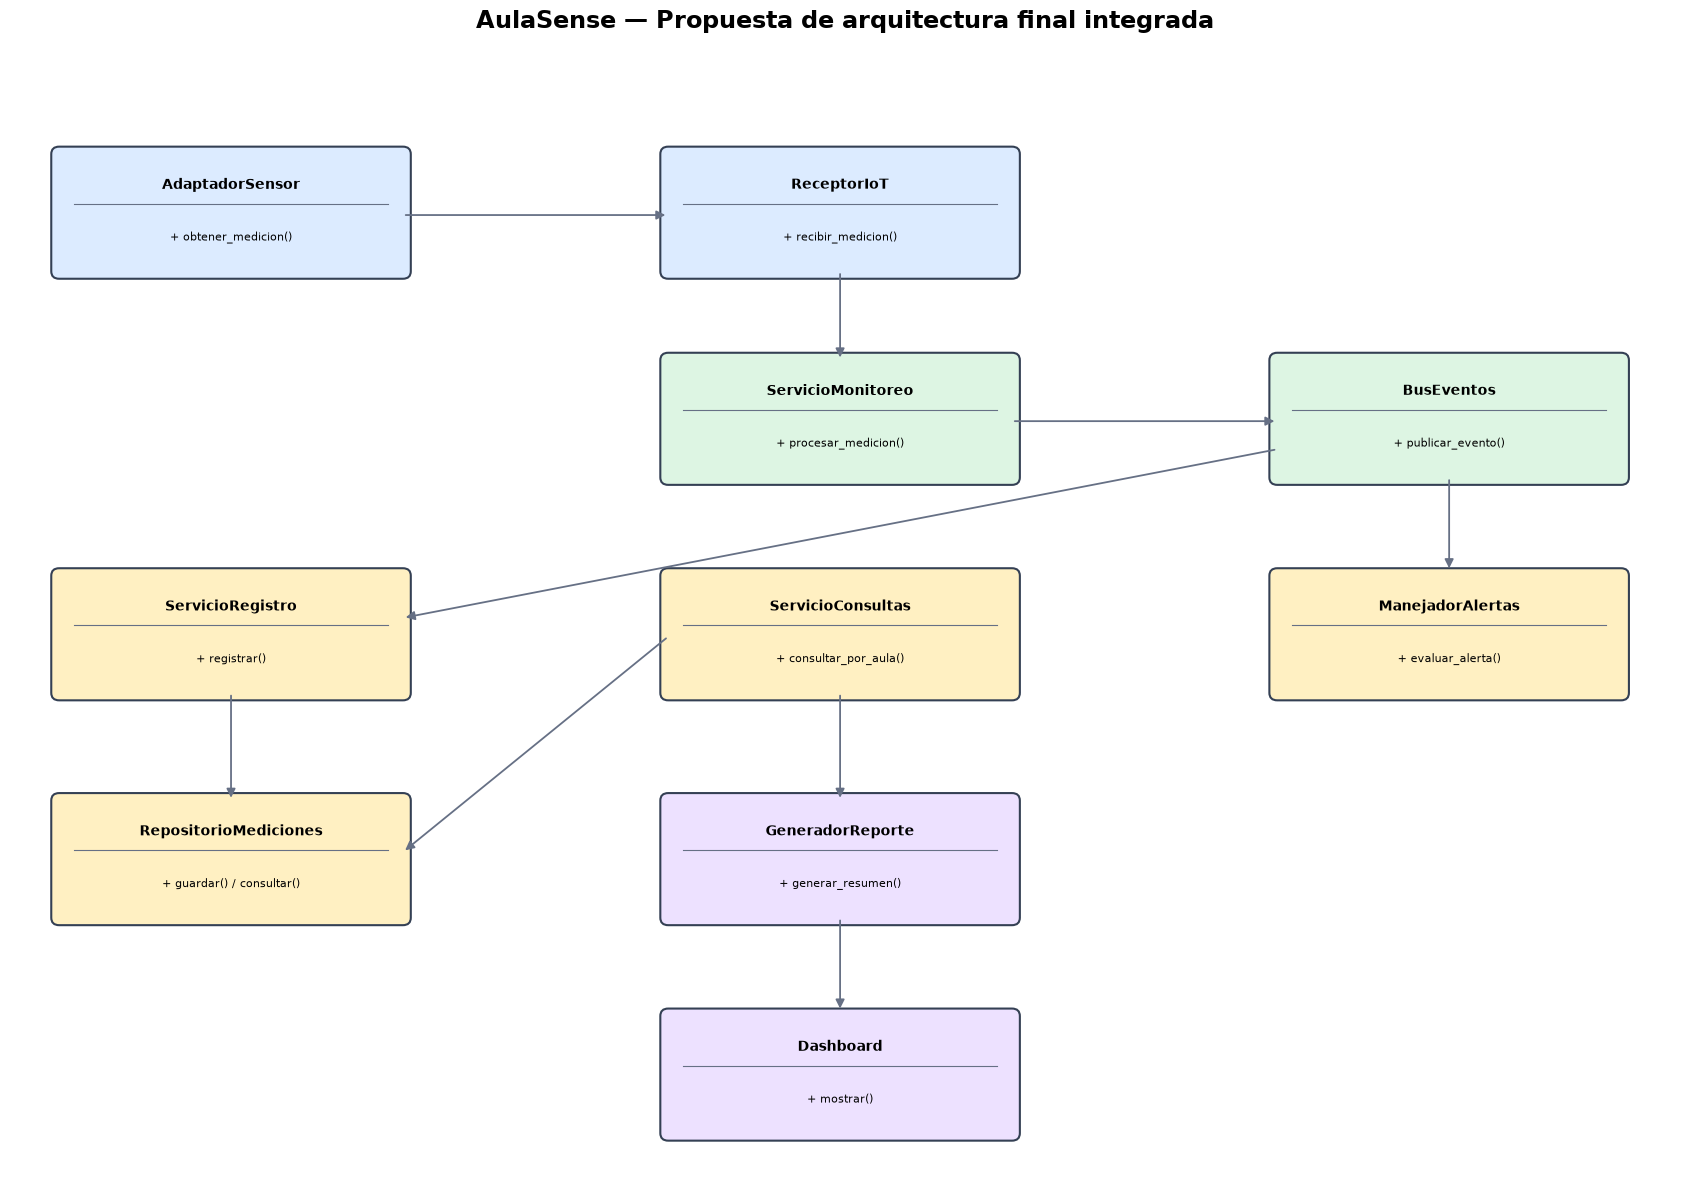

In [3]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(17, 12))
ax.set_xlim(0, 17)
ax.set_ylim(0, 12)
ax.axis("off")

def clase(nombre, atributos, x, y, color):
    ancho, alto = 3.5, 1.25

    caja = FancyBboxPatch(
        (x, y), ancho, alto,
        boxstyle="round,pad=0.08",
        linewidth=1.5,
        edgecolor="#344054",
        facecolor=color
    )
    ax.add_patch(caja)

    ax.text(x + ancho / 2, y + 0.92, nombre,
            ha="center", va="center",
            fontsize=10, fontweight="bold")

    ax.plot([x + 0.15, x + ancho - 0.15],
            [y + 0.72, y + 0.72],
            color="#667085", linewidth=0.8)

    ax.text(x + ancho / 2, y + 0.36, atributos,
            ha="center", va="center", fontsize=8)

def conectar(origen, destino):
    flecha = FancyArrowPatch(
        origen, destino,
        arrowstyle="-|>",
        mutation_scale=13,
        linewidth=1.3,
        color="#667085"
    )
    ax.add_patch(flecha)

azul = "#DCEBFF"
verde = "#DDF5E3"
amarillo = "#FFF0C2"
morado = "#EDE1FF"

# Capa de sensores
clase("AdaptadorSensor", "+ obtener_medicion()", 0.5, 9.7, azul)
clase("ReceptorIoT", "+ recibir_medicion()", 6.7, 9.7, azul)

# Capa de procesamiento
clase("ServicioMonitoreo", "+ procesar_medicion()", 6.7, 7.5, verde)
clase("BusEventos", "+ publicar_evento()", 12.9, 7.5, verde)

# Capa de servicios
clase("ServicioRegistro", "+ registrar()", 0.5, 5.2, amarillo)
clase("RepositorioMediciones", "+ guardar() / consultar()", 0.5, 2.8, amarillo)
clase("ServicioConsultas", "+ consultar_por_aula()", 6.7, 5.2, amarillo)
clase("ManejadorAlertas", "+ evaluar_alerta()", 12.9, 5.2, amarillo)

# Capa de presentación
clase("GeneradorReporte", "+ generar_resumen()", 6.7, 2.8, morado)
clase("Dashboard", "+ mostrar()", 6.7, 0.5, morado)

# Relaciones principales
conectar((4.0, 10.3), (6.7, 10.3))
conectar((8.45, 9.7), (8.45, 8.75))
conectar((10.2, 8.1), (12.9, 8.1))
conectar((12.9, 7.8), (4.0, 6.0))
conectar((14.65, 7.5), (14.65, 6.5))
conectar((2.25, 5.2), (2.25, 4.05))
conectar((6.7, 5.8), (4.0, 3.5))
conectar((8.45, 5.2), (8.45, 4.05))
conectar((8.45, 2.8), (8.45, 1.8))

ax.set_title(
    "AulaSense — Propuesta de arquitectura final integrada",
    fontsize=17, fontweight="bold", pad=20
)

plt.tight_layout()
plt.show()

## Conclusión general

El análisis de AulaSense permitió identificar los problemas que
pueden surgir cuando una sola clase concentra demasiadas
responsabilidades, como la dificultad para realizar cambios,
probar componentes y agregar nuevas funcionalidades.

Cada integrante propuso una solución diferente para mejorar
la organización del sistema. Después de comparar las cuatro
alternativas, se decidió plantear una arquitectura modular por
capas que integra sus principales ventajas.

La propuesta final distribuye las responsabilidades entre
componentes especializados para la recepción de datos IoT,
el procesamiento de mediciones, el almacenamiento, las
consultas, la generación de reportes y las alertas.

Con esta organización se busca facilitar el mantenimiento,
la reutilización del código, las pruebas individuales y la
incorporación de nuevas funcionalidades.

Aunque la arquitectura integrada todavía es una propuesta
de diseño y no un sistema completamente implementado,
representa una base más organizada para continuar con el
desarrollo de AulaSense.